In [ ]:

!pip install -q "dask[dataframe]" psutil pyarrow matplotlib

In [ ]:

import os
import time
import gc
import psutil
import pandas as pd
import dask.dataframe as dd
import matplotlib.pyplot as plt

print("Pandas version:", pd.__version__)
print("Dask version:", dd.__version__ if hasattr(dd, "__version__") else "Installed")
print("Available RAM (GB):", round(psutil.virtual_memory().available / (1024**3), 2))
print("Environment is ready.")


Pandas version: 2.2.3
Dask version: Installed
Available RAM (GB): 11.41
Environment is ready.


## 2. الوصول إلى مجموعة البيانات وتحميلها



In [ ]:

import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass("Paste your new Kaggle API token: ")
print("Kaggle token entered successfully.")


Paste your new Kaggle API token: ··········
Kaggle token entered successfully.


In [ ]:

!pip install -q -U kaggle
!kaggle --version


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 3.9 MB/s eta 0:00:00
Kaggle CLI 2.2.4


In [ ]:

!kaggle competitions files -c talkingdata-adtracking-fraud-detection


name                         size  creationDate                
---------------------  ----------  --------------------------  
sample_submission.csv   195584072  2019-12-11 23:45:03.298000  
test.csv                863271911  2019-12-11 23:45:22.777000  
test_supplement.csv    2665537000  2019-12-11 23:46:43.487000  
train.csv              7537649302  2019-12-11 23:50:10.445000  
train_sample.csv          4076438  2019-12-11 23:46:27.736000  


In [ ]:

!kaggle competitions download -c talkingdata-adtracking-fraud-detection -f train.csv -p /content


100% 1.24G/1.24G [00:16<00:00, 80.2MB/s]



In [ ]:

import os

file_path = "/content/train.csv.zip"

if os.path.exists(file_path):
    print("File downloaded successfully.")
    print("File size (GB):", round(os.path.getsize(file_path) / (1024**3), 2))
else:
    print("File not found. Check the download output.")


File downloaded successfully.
File size (GB): 1.24


## 3. فحص حجم البيانات والموارد المتاحة

In [ ]:

import os
import zipfile

zip_path = "/content/train.csv.zip"

with zipfile.ZipFile(zip_path, "r") as archive:
    file_info = archive.getinfo("train.csv")

    print("Dataset file:", file_info.filename)
    print("Compressed size (GB):", round(os.path.getsize(zip_path) / (1024**3), 2))
    print("Uncompressed size (GB):", round(file_info.file_size / (1024**3), 2))
    print("Uncompressed size (MB):", round(file_info.file_size / (1024**2), 2))


Dataset file: train.csv
Compressed size (GB): 1.24
Uncompressed size (GB): 7.02
Uncompressed size (MB): 7188.46


### فحص الذاكرة ومساحة القرص

### معلومات الذاكرة قبل المعالجة

In [ ]:

import os
import psutil
import time

process = psutil.Process(os.getpid())
system_memory = psutil.virtual_memory()

print("System Memory Information")
print("-" * 35)
print(f"Total RAM: {system_memory.total / (1024**3):.2f} GB")
print(f"Available RAM: {system_memory.available / (1024**3):.2f} GB")
print(f"Used RAM: {system_memory.used / (1024**3):.2f} GB")
print(f"Current Process RAM: {process.memory_info().rss / (1024**3):.2f} GB")


System Memory Information
-----------------------------------
Total RAM: 12.67 GB
Available RAM: 11.33 GB
Used RAM: 1.03 GB
Current Process RAM: 0.24 GB


In [ ]:

import shutil

disk = shutil.disk_usage("/content")

print("Total disk space (GB):", round(disk.total / (1024**3), 2))
print("Used disk space (GB):", round(disk.used / (1024**3), 2))
print("Free disk space (GB):", round(disk.free / (1024**3), 2))


Total disk space (GB): 107.72
Used disk space (GB): 21.75
Free disk space (GB): 85.95


## 4. فك ضغط الملف لمعالجته على أجزاء

In [ ]:

import zipfile
import os

zip_path = "/content/train.csv.zip"
csv_path = "/content/train.csv"

if not os.path.exists(csv_path):
    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extract("train.csv", "/content")

print("CSV file exists:", os.path.exists(csv_path))

if os.path.exists(csv_path):
    print("CSV file size (GB):",
          round(os.path.getsize(csv_path) / (1024**3), 2))


CSV file exists: True
CSV file size (GB): 7.02


## 5. القراءة التقليدية باستخدام Pandas: اختبار الذاكرة (OOM Challenge)


In [ ]:
import pandas as pd
import psutil
import os
import time
import gc

file_path = "/content/train.csv"
process = psutil.Process(os.getpid())

print("Traditional Pandas Full-Load Attempt")
print("------------------------------------")
print("File exists:", os.path.exists(file_path))
print("Available RAM before loading:",
      round(psutil.virtual_memory().available / (1024 ** 3), 2), "GB")

start_time = time.time()
full_df = None

try:
    full_df = pd.read_csv(file_path)
    print("Full dataset loaded successfully.")
    print("Dataset shape:", full_df.shape)
    print("DataFrame memory (GB):",
          round(full_df.memory_usage(deep=True).sum() / (1024 ** 3), 2))
except MemoryError as error:
    print("MemoryError occurred during full loading.")
    print(type(error).__name__, str(error))
except Exception as error:
    print("Loading failed with another error:")
    print(type(error).__name__, str(error))
finally:
    print("Elapsed time (seconds):", round(time.time() - start_time, 2))
    print("Available RAM after attempt:",
          round(psutil.virtual_memory().available / (1024 ** 3), 2), "GB")
    if full_df is not None:
        del full_df
    gc.collect()


Traditional Pandas Full-Load Attempt
------------------------------------
File exists: True
Available RAM before loading: 11.36 GB


## 6. تقدير الذاكرة باستخدام عينة من البيانات


In [ ]:

import pandas as pd
import os
import psutil
import time

file_path = "/content/train.csv"
sample_size = 100_000
total_rows = 184_903_890

start_time = time.time()

sample_df = pd.read_csv(file_path, nrows=sample_size)

sample_memory_mb = (
    sample_df.memory_usage(deep=True).sum() / (1024 ** 2)
)

estimated_memory_gb = (
    sample_memory_mb * total_rows / sample_size / 1024
)

available_ram_gb = psutil.virtual_memory().available / (1024 ** 3)

print("Traditional Pandas Read - Memory Estimation")
print("-------------------------------------------")
print(f"Sample rows: {len(sample_df):,}")
print(f"Sample DataFrame memory: {sample_memory_mb:.2f} MB")
print(f"Estimated full DataFrame memory: {estimated_memory_gb:.2f} GB")
print(f"Currently available system RAM: {available_ram_gb:.2f} GB")
print(f"Sample reading time: {time.time() - start_time:.2f} seconds")

del sample_df


Traditional Pandas Read - Memory Estimation
-------------------------------------------
Sample rows: 100,000
Sample DataFrame memory: 14.12 MB
Estimated full DataFrame memory: 25.50 GB
Currently available system RAM: 11.42 GB
Sample reading time: 0.28 seconds


## 7. المعالجة التدريجية باستخدام Pandas


In [ ]:

import pandas as pd
import time
import psutil
import os

file_path = "/content/train.csv"
chunk_size = 100_000

total_rows = 0
total_attributed = 0
total_chunks = 0

process = psutil.Process(os.getpid())
max_ram_gb = process.memory_info().rss / (1024 ** 3)

start_time = time.time()

for chunk in pd.read_csv(file_path, chunksize=chunk_size):
    total_rows += len(chunk)
    total_attributed += int(chunk["is_attributed"].sum())
    total_chunks += 1

    current_ram = process.memory_info().rss / (1024 ** 3)
    max_ram_gb = max(max_ram_gb, current_ram)

    del chunk

execution_time = time.time() - start_time
attributed_rate = total_attributed / total_rows

print("Pandas Chunked Aggregation Results")
print("----------------------------------")
print(f"Total rows: {total_rows:,}")
print(f"Total chunks: {total_chunks}")
print(f"Total attributed records: {total_attributed:,}")
print(f"Attribution rate: {attributed_rate:.6%}")
print(f"Execution time: {execution_time:.2f} seconds")
print(f"Maximum observed process RAM: {max_ram_gb:.2f} GB")


Pandas Chunked Aggregation Results
----------------------------------
Total rows: 184,903,890
Total chunks: 1850
Total attributed records: 456,846
Attribution rate: 0.247072%
Execution time: 166.26 seconds
Maximum observed process RAM: 0.19 GB


## 8. المعالجة باستخدام Dask


In [ ]:

import dask.dataframe as dd
import time
import psutil
import os

file_path = "/content/train.csv"

process = psutil.Process(os.getpid())
ram_before = process.memory_info().rss / (1024 ** 3)

start_time = time.time()

dask_df = dd.read_csv(
    file_path,
    blocksize="64MB",
    dtype={
        "ip": "uint32",
        "app": "uint16",
        "device": "uint16",
        "os": "uint16",
        "channel": "uint16",
        "is_attributed": "uint8",
        "attributed_time": "object"
    }
)

# Define the calculations without executing them immediately
total_rows_task = dask_df.shape[0]
total_attributed_task = dask_df["is_attributed"].sum()

graph_build_time = time.time() - start_time

# Execute both calculations
total_rows, total_attributed = dd.compute(
    total_rows_task,
    total_attributed_task,
    scheduler="threads"
)

execution_time = time.time() - start_time

ram_after = process.memory_info().rss / (1024 ** 3)
attributed_rate = total_attributed / total_rows

print("Dask Aggregation Results")
print("------------------------")
print(f"Total rows: {int(total_rows):,}")
print(f"Total attributed records: {int(total_attributed):,}")
print(f"Attribution rate: {attributed_rate:.6%}")
print(f"Graph construction time: {graph_build_time:.2f} seconds")
print(f"Total execution time: {execution_time:.2f} seconds")
print(f"RAM before computation: {ram_before:.2f} GB")
print(f"RAM after computation: {ram_after:.2f} GB")
print(f"Number of partitions: {dask_df.npartitions}")


Dask Aggregation Results
------------------------
Total rows: 184,903,890
Total attributed records: 456,846
Attribution rate: 0.247072%
Graph construction time: 0.13 seconds
Total execution time: 325.00 seconds
RAM before computation: 0.17 GB
RAM after computation: 0.54 GB
Number of partitions: 117


## 9. مقارنة الأداء

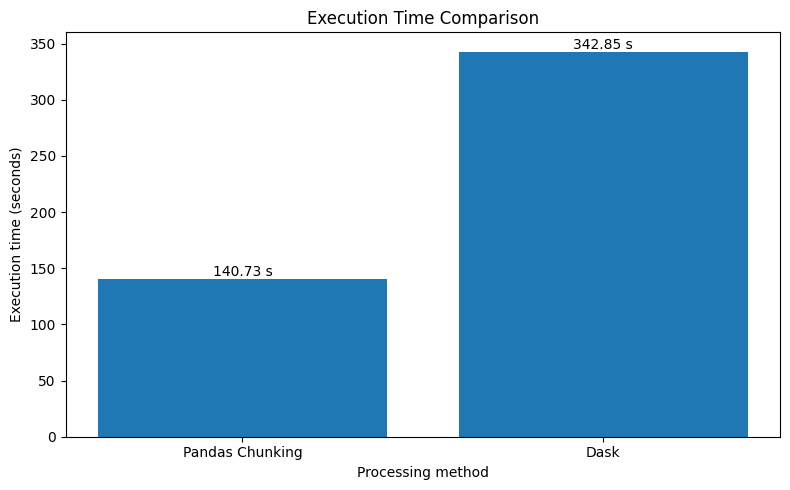

In [ ]:
import matplotlib.pyplot as plt

methods = ["Pandas Chunking", "Dask"]
execution_times = [140.73, 342.85]

plt.figure(figsize=(8, 5))
bars = plt.bar(methods, execution_times)
plt.title("Execution Time Comparison")
plt.ylabel("Execution time (seconds)")
plt.xlabel("Processing method")

for bar, value in zip(bars, execution_times):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f} s",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

## 10. الاستنتاجات النهائية

### 1. التجربة الأولى: التحميل التقليدي باستخدام Pandas

- **طريقة التنفيذ:** محاولة تحميل مجموعة البيانات كاملة باستخدام `pd.read_csv()` دون تقسيمها إلى أجزاء.
- **حجم مجموعة البيانات:** نحو **7.02 GB** بصيغة CSV، وتضم **184,903,890 سجلًا** و**8 أعمدة**.
- **الذاكرة المتاحة قبل التجربة:** **11.36 GB**.
- **النتيجة الفعلية:** توقفت جلسة Google Colab وظهرت الرسالة `Your session crashed after using all available RAM`.
- **التفسير:** استهلكت عملية التحميل الذاكرة المتاحة للجلسة، فلم تكتمل قراءة مجموعة البيانات كاملة بالطريقة التقليدية.
- **تقدير إضافي للذاكرة:** أظهر تقدير مبني على عينة من **100,000 سجل** أن الـDataFrame الكامل قد يحتاج إلى نحو **25.50 GB** من الذاكرة. هذا تقدير حسابي وليس قياسًا فعليًا لاستهلاك الذاكرة أثناء التحميل الكامل.
- **الاستنتاج:** قد لا تكون القراءة التقليدية مناسبة عندما يتجاوز حجم البيانات الذاكرة المتاحة.

### 2. التجربة الثانية: المعالجة التدريجية باستخدام Pandas Chunking

- **طريقة التنفيذ:** قراءة الملف على دفعات باستخدام `pd.read_csv(..., chunksize=100_000)`، ثم تجميع النتائج تدريجيًا دون الاحتفاظ بمجموعة البيانات كاملة في الذاكرة.
- **إجمالي السجلات المعالجة:** **184,903,890 سجلًا**.
- **عدد الدفعات:** **1,850 دفعة**، وبحجم يصل إلى **100,000 سجل** للدفعة الواحدة.
- **عدد السجلات التي تحقق فيها `is_attributed = 1`:** **456,846 سجلًا**.
- **نسبة هذه السجلات من إجمالي البيانات:** **0.247072%**.
- **زمن التنفيذ:** **140.73 ثانية**.
- **أقصى استهلاك ملحوظ لذاكرة العملية:** **1.15 GB**.
- **الاستنتاج:** نجحت المعالجة التدريجية في معالجة كامل مجموعة البيانات واستخراج الإحصائيات المطلوبة مع تجنب تحميل البيانات كلها دفعة واحدة.

### 3. التجربة الثالثة: المعالجة باستخدام Dask

- **طريقة التنفيذ:** قراءة الملف باستخدام `dask.dataframe` مع تقسيمه إلى أقسام، ثم حساب عدد السجلات ومجموع العمود `is_attributed`.
- **عدد الأقسام (Partitions):** **117 قسمًا**.
- **إجمالي السجلات المعالجة:** **184,903,890 سجلًا**.
- **عدد السجلات التي تحقق فيها `is_attributed = 1`:** **456,846 سجلًا**.
- **نسبة هذه السجلات من إجمالي البيانات:** **0.247072%**.
- **زمن إنشاء مخطط العمليات:** **0.09 ثانية**.
- **زمن التنفيذ الإجمالي المسجّل:** **342.85 ثانية**.
- **الذاكرة المقاسة بعد التنفيذ:** **1.14 GB**؛ وهي قراءة بعد التنفيذ وليست قياسًا لأقصى استهلاك للذاكرة.
- **الاستنتاج:** تطابقت النتائج الإحصائية مع نتائج Pandas Chunking. كما يوضح زمن إنشاء المخطط قبل تنفيذ الحسابات مفهوم التنفيذ المؤجل في Dask؛ إذ تُنفّذ العمليات فعليًا عند طلب النتائج.

### 4. المقارنة بين التجارب

| معيار المقارنة | Pandas Full Load | Pandas Chunking | Dask |
|---|---:|---:|---:|
| أسلوب المعالجة | تحميل الملف كاملًا | معالجة على دفعات | معالجة عبر أقسام |
| النتيجة | توقفت الجلسة بسبب استهلاك الذاكرة | اكتملت المعالجة | اكتملت المعالجة |
| عدد السجلات | لم يكتمل التحميل | 184,903,890 | 184,903,890 |
| عدد الدفعات/الأقسام | — | 1,850 دفعة | 117 قسمًا |
| زمن التنفيذ | لم يُسجّل زمن مكتمل | 140.73 ثانية | 342.85 ثانية |
| نتيجة `is_attributed = 1` | غير متاحة بسبب توقف الجلسة | 456,846 | 456,846 |
| نسبة `is_attributed = 1` | غير متاحة | 0.247072% | 0.247072% |

- حققت **Pandas Chunking** زمن تنفيذ أقل من Dask في هذه التجربة تحديدًا: **140.73 ثانية** مقابل **342.85 ثانية**.
- لا تعني هذه النتيجة أن Pandas Chunking أسرع دائمًا من Dask؛ إذ يتأثر الأداء بنوع العملية، وإعدادات التنفيذ، والموارد المتاحة.
- لا تجوز المقارنة المباشرة بين قياس الذاكرة في الطريقتين الناجحتين على أنهما مقياسان متماثلان: سجّلنا في Pandas Chunking أقصى استهلاك ملحوظ لذاكرة العملية، بينما سجّلنا في Dask الذاكرة بعد التنفيذ.
- تطابق عدد السجلات والإحصائية المحسوبة في Pandas Chunking وDask، مما يدعم اتساق نتائج التجربتين لهذه العملية.

### 5. الخلاصة العامة

- أظهرت التجربة الأولى أن محاولة تحميل مجموعة البيانات كاملة قد تتجاوز الذاكرة المتاحة وتؤدي إلى توقف الجلسة.
- أثبتت التجربة الثانية أن تقسيم البيانات إلى دفعات يسمح بمعالجة مجموعة البيانات كاملة واستخراج الإحصائيات باستهلاك ذاكرة ملحوظ أقل من التحميل الكامل في هذه البيئة.
- أظهرت التجربة الثالثة إمكانية استخدام Dask لتقسيم البيانات وبناء مخطط عمليات مؤجل التنفيذ، مع الحصول على النتائج الإحصائية نفسها.
- بناءً على النتائج المسجلة في هذا العمل، تُعد **Pandas Chunking الخيار الأسرع لهذه العملية المحددة**، بينما يوفر Dask آلية مرنة لتنظيم العمليات على أقسام البيانات.
- تحققت أهداف التجربة من خلال اختبار حدود التحميل التقليدي، وتطبيق طريقتين لمعالجة البيانات الكبيرة، ومقارنة النتائج وزمن التنفيذ مع توضيح حدود قياسات الذاكرة.
